# 01 · Quality control, batch correction, and clustering

This notebook is the starting point of the analysis. It takes the six Visium timepoints (0 hpa to 7 dpa), puts them into one dataset, and turns raw counts into a batch-corrected embedding with spot clusters and preliminary cell-type labels. Later notebooks build on this output.

**Steps**

1. Load and combine the six timepoints
2. Quality control
3. Normalization, highly variable genes, and PCA
4. Batch correction with Harmony
5. Clustering and choice of resolution
6. Marker genes and preliminary cell-type labels
7. Neoblast clusters
8. Marker dot plot
9. Save the processed data

**Input:** `data/Scanpy_Visium/Visium_*.h5ad` (raw counts, one file per timepoint) and `data/smed_blast.csv` (planarian gene ID to human gene symbol).
**Output:** `data/processed/01_integrated.h5ad`.

> **Note:** Background notes on the methods (why batch correction is needed, how Harmony works) are in [`docs/notes.md`](../docs/notes.md).

In [1]:
import os

import anndata as ad
import harmonypy as hm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

sc.settings.verbosity = 1
sc.set_figure_params(dpi=80, facecolor='white')
np.random.seed(42)

DATA_DIR = '../data/Scanpy_Visium'
OUT_DIR = '../data/processed'
FIG_DIR = '../figures'
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Load and combine the six timepoints

**What.** Read one file per timepoint, label every spot with its timepoint, and concatenate them into one AnnData object. Spot names get a timepoint prefix so they stay unique.

**Why combine.** Processing all timepoints together gives them one shared set of highly variable genes, one shared PCA space, and one shared set of clusters. A cluster labeled "neoblast" then means the same thing at every timepoint, which is what makes later comparisons across time possible. Combining does not change any expression values by itself.

**Parameters.** `join='inner'` keeps only genes present in all six files (here all 27,664 genes are shared).

In [2]:
tp_files = [
    ('0hpa',  'Visium_0hpa.h5ad'),
    ('6hpa',  'Visium_6hpa.h5ad'),
    ('12hpa', 'Visium_12hpa.h5ad'),
    ('1dpa',  'Visium_1dpa.h5ad'),
    ('3dpa',  'Visium_3dpa.h5ad'),
    ('7dpa',  'Visium_7dpa.h5ad'),
]

slices = []
for tp, fname in tp_files:
    a = sc.read_h5ad(os.path.join(DATA_DIR, fname))
    a.obs['timepoint'] = tp
    a.obs_names = [f'{tp}_{c}' for c in a.obs_names]
    a.uns.pop('spatial', None)  # H&E images are not needed here
    # Aligned coordinates are stored as categories; convert to numbers
    # (mixed category types across files otherwise break writing to .h5ad)
    for col in ['Aligned_X', 'Aligned_Y', 'Aligned_Z']:
        a.obs[col] = pd.to_numeric(a.obs[col].astype(str), errors='coerce')
    slices.append(a)
    print(tp, a.shape)

combined = ad.concat(slices, join='inner')
combined.var_names_make_unique()
del slices

TP_ORDER = [tp for tp, _ in tp_files]
combined.obs['timepoint'] = pd.Categorical(
    combined.obs['timepoint'], categories=TP_ORDER, ordered=True
)
print('Combined dataset:', combined.shape)

0hpa (8949, 27664)


6hpa (7304, 27664)


12hpa (10156, 27664)


1dpa (8423, 27664)


3dpa (8365, 27664)


7dpa (10210, 27664)


Combined dataset: (53407, 27664)


In [3]:
# Gene ID lookup: planarian SMED IDs <-> human gene symbols (BLAST best hit)
blast = pd.read_csv('../data/smed_blast.csv').dropna(subset=['gene_symbol'])
blast = blast.drop_duplicates('smed_id')

id2sym = dict(zip(blast['smed_id'], blast['gene_symbol']))
sym2ids = blast.groupby('gene_symbol')['smed_id'].apply(list).to_dict()

print(f'{len(id2sym):,} SMED IDs mapped to human gene symbols')

13,541 SMED IDs mapped to human gene symbols


## 2. Quality control

**What.** Compute per-spot total counts and number of detected genes, then remove low-quality spots and rarely detected genes.

**Why.** Spots with very few counts are usually at the tissue edge or poorly captured. Their expression profiles are dominated by noise and tend to form artificial clusters. Genes seen in only a handful of spots carry almost no information and only add noise to later steps.

**Parameters.**
- `min_counts=500` and `min_genes=200` per spot: removes the low tail of the distributions below while keeping almost all spots.
- `min_cells=10` per gene: keeps any gene detected in at least 10 spots.

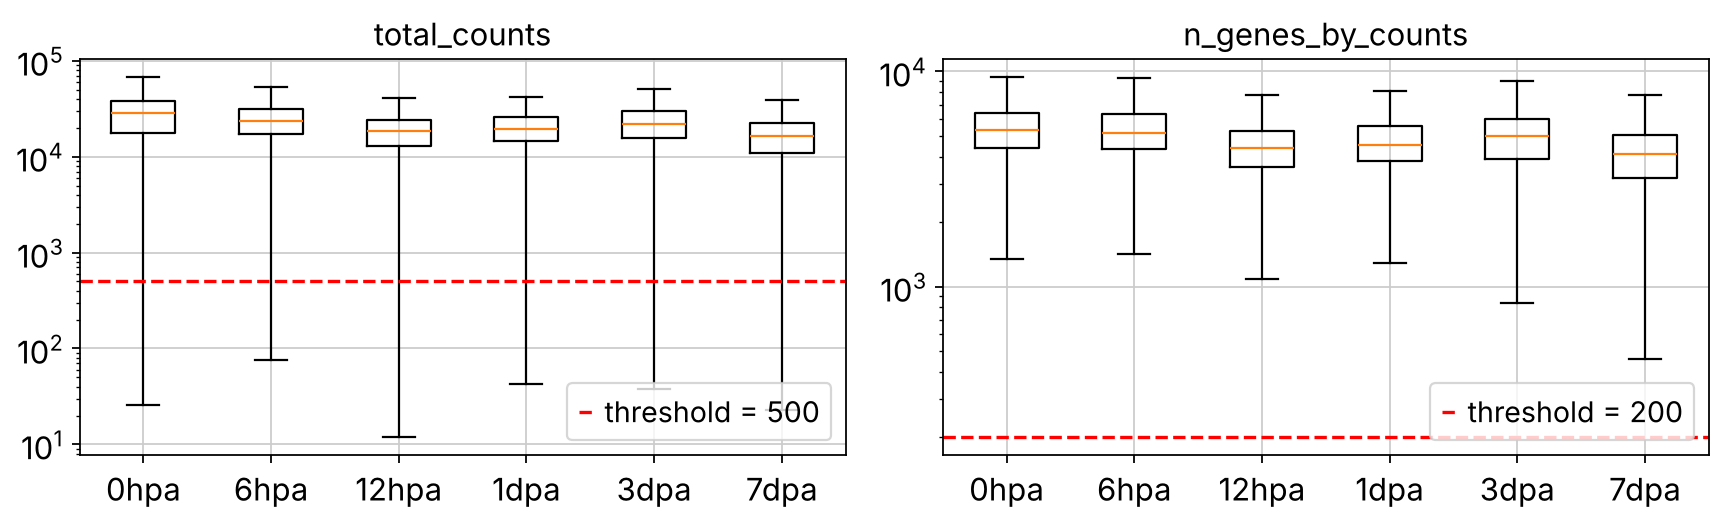

Spots: 53,407 -> 52,856 (551 removed)
Genes: 27,664 -> 22,333 (5,331 removed)
timepoint
0hpa      8715
6hpa      7287
12hpa     9977
1dpa      8389
3dpa      8336
7dpa     10152
Name: count, dtype: int64


In [4]:
sc.pp.calculate_qc_metrics(combined, percent_top=None, log1p=False, inplace=True)

# Distributions per timepoint, with the chosen thresholds
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, key, thr in zip(axes, ['total_counts', 'n_genes_by_counts'], [500, 200]):
    data = [combined.obs.loc[combined.obs['timepoint'] == tp, key] for tp in TP_ORDER]
    ax.boxplot(data, tick_labels=TP_ORDER, showfliers=False)
    ax.axhline(thr, color='red', linestyle='--', label=f'threshold = {thr}')
    ax.set_yscale('log')
    ax.set_title(key)
    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

n_spots0, n_genes0 = combined.shape
sc.pp.filter_cells(combined, min_counts=500)
sc.pp.filter_cells(combined, min_genes=200)
sc.pp.filter_genes(combined, min_cells=10)
print(f'Spots: {n_spots0:,} -> {combined.n_obs:,} '
      f'({n_spots0 - combined.n_obs:,} removed)')
print(f'Genes: {n_genes0:,} -> {combined.n_vars:,} '
      f'({n_genes0 - combined.n_vars:,} removed)')
print(combined.obs['timepoint'].value_counts().reindex(TP_ORDER))

**Result.** Spot quality is high overall: median total counts are around 15,000–30,000 per timepoint, and the 500-count threshold only trims the extreme low tail. QC removed 551 spots (1.0%) and 5,331 rarely detected genes, leaving 52,856 spots × 22,333 genes. Every timepoint keeps 7,000–10,000 spots, so no timepoint is under-represented after filtering.

## 3. Normalization, highly variable genes, and PCA

**What.**
1. Scale each spot to 10,000 total counts, then log-transform.
2. Select 2,000 highly variable genes (HVGs).
3. Scale each HVG to unit variance and run PCA (50 components).

**Why.**
- Spots differ in sequencing depth. Normalization removes that difference so that expression levels can be compared between spots. The log transform reduces the influence of a few very highly expressed genes.
- Most genes vary little between spots. Restricting to HVGs keeps the biological signal and cuts noise and compute time.
- PCA compresses the 2,000 genes into 50 axes that capture most of the variation. Clustering and UMAP are run on this compressed space.

**Parameters.**
- `batch_key='timepoint'` in HVG selection: genes are ranked within each timepoint and then combined, so a gene that is variable only because one timepoint differs from the rest overall is less likely to be selected.
- `max_value=10` when scaling: clips extreme values so a few outlier spots cannot dominate a component.
- Raw counts are kept in `layers['counts']` for later use (for example, differential expression).

HVGs selected: 2000


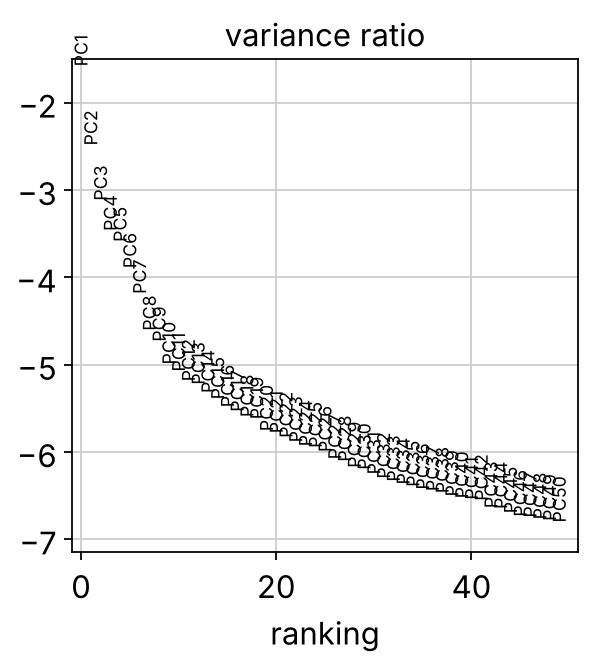

In [5]:
combined.layers['counts'] = combined.X.copy()
sc.pp.normalize_total(combined, target_sum=1e4)
sc.pp.log1p(combined)

sc.pp.highly_variable_genes(
    combined, n_top_genes=2000, batch_key='timepoint', flavor='seurat'
)
print('HVGs selected:', combined.var['highly_variable'].sum())

# Scale and run PCA on the HVG subset only; the full matrix stays log-normalized
hvg = combined[:, combined.var['highly_variable']].copy()
sc.pp.scale(hvg, max_value=10)
sc.tl.pca(hvg, n_comps=50, svd_solver='arpack')
combined.obsm['X_pca'] = hvg.obsm['X_pca']
combined.uns['pca'] = hvg.uns['pca']
del hvg

sc.pl.pca_variance_ratio(combined, n_pcs=50, log=True)

**Result.** 2,000 HVGs were selected. The first few PCs carry most of the variance, and the curve levels off gradually after about PC 20.

## 4. Batch correction with Harmony

**What.** First build a UMAP on the uncorrected PCA to check whether spots separate by timepoint. Then run Harmony on the 50 PCs, with timepoint as the batch variable, and rebuild the neighbor graph and UMAP on the corrected embedding.

**Why.** Each timepoint was collected as a separate Visium experiment, with different animals, slides, and sequencing runs. Normalization only corrects for sequencing depth within each spot; it does not remove systematic differences between experiments, which affect different genes by different amounts. Without correction, the same tissue type from two timepoints can land in different places in PCA/UMAP, and clusters end up splitting by experiment instead of by biology. Harmony moves spots in PCA space so that, within each group of similar spots, the timepoints are mixed. It changes only the embedding; the expression matrix is left as it is.

**Parameters.**
- Batch variable: `timepoint`. Each timepoint is a separate experiment.
- `max_iter_harmony=10`, default `theta=2` (strength of the push toward mixing).
- Neighbor graph: 20 neighbors on the first 30 corrected PCs. In the variance plot above, most of the drop happens within the first ~20 PCs; using 30 keeps a margin without adding much noise.

In [6]:
# Uncorrected embedding, for comparison
sc.pp.neighbors(combined, use_rep='X_pca', n_neighbors=20, n_pcs=30)
sc.tl.umap(combined, min_dist=0.3)
combined.obsm['X_umap_uncorrected'] = combined.obsm['X_umap'].copy()

In [7]:
# Call harmonypy directly — sc.external.pp.harmony_integrate mis-handles
# the output shape with newer harmonypy/PyTorch backends
pca = np.asarray(combined.obsm['X_pca'], dtype=np.float64)
ho = hm.run_harmony(pca, combined.obs, 'timepoint', random_state=0,
                    max_iter_harmony=10, verbose=False)

Z = ho.Z_corr
if hasattr(Z, 'detach'):        # move off MPS/GPU if needed
    Z = Z.detach().cpu().numpy()
Z = np.asarray(Z, dtype=np.float64)
if Z.shape != pca.shape:        # harmony may return (n_pcs, n_cells)
    Z = Z.T
assert Z.shape == pca.shape, (Z.shape, pca.shape)
combined.obsm['X_pca_harmony'] = Z

# Neighbor graph and UMAP on the Harmony-corrected embedding
sc.pp.neighbors(combined, use_rep='X_pca_harmony', n_neighbors=20, n_pcs=30)
sc.tl.umap(combined, min_dist=0.3)

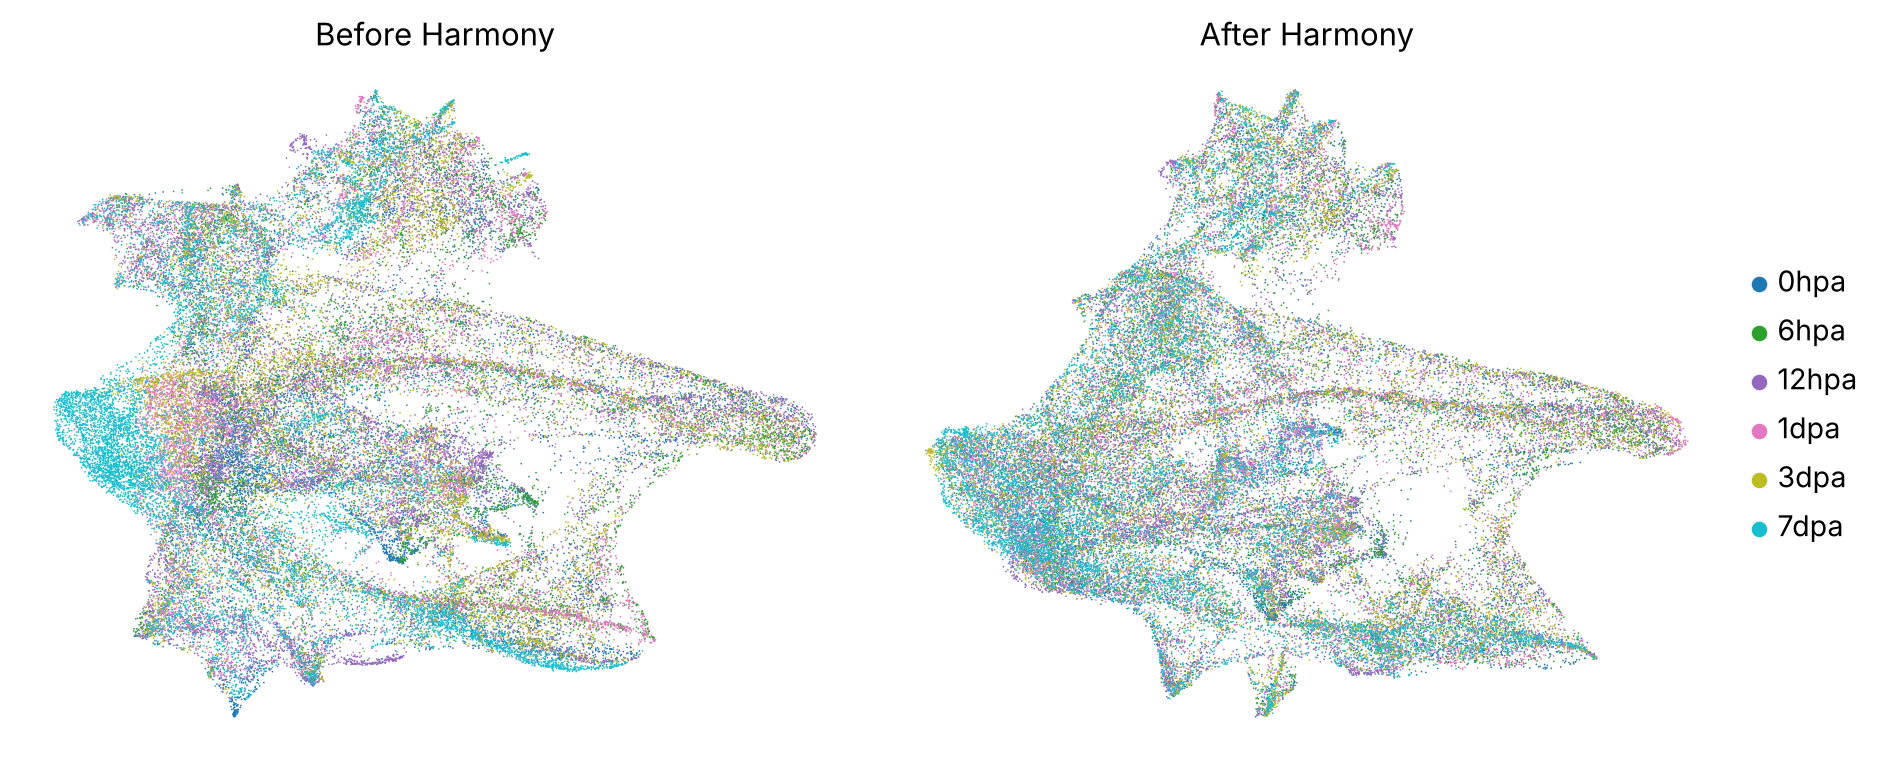

In [8]:
# Before vs after, colored by timepoint
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sc.pl.embedding(combined, basis='X_umap_uncorrected', color='timepoint',
                ax=axes[0], show=False, frameon=False, palette='tab10',
                title='Before Harmony', legend_loc=None)
sc.pl.umap(combined, color='timepoint', ax=axes[1], show=False,
           frameon=False, palette='tab10', title='After Harmony')
plt.tight_layout()
fig.savefig(f'{FIG_DIR}/01_umap_harmony.png', dpi=150, bbox_inches='tight')
plt.show()

**Result.** Before correction, some regions of the UMAP are made up mostly of one timepoint (most clearly the 7 dpa spots on the left and along the bottom edge). After Harmony, all six timepoints are interleaved across the whole embedding, so the remaining structure reflects tissue composition rather than which experiment a spot came from.

> **Note:** Timepoint is both the batch and the biological variable of interest here. Harmony cannot tell technical differences from real ones, so it may also smooth out some true changes over time. Cell-type proportions per timepoint are still usable (they are counts within clusters), but changes in expression over time should be tested on the expression matrix, not on the corrected embedding.

## 5. Clustering and choice of resolution

**What.** Run Leiden clustering on the Harmony-corrected neighbor graph at four resolutions (0.2, 0.4, 0.6, 0.8) and compare them.

**Why.** Resolution sets how finely the graph is split. Too low merges distinct tissue types; too high splits one tissue type into several clusters that differ only by noise. There is no single correct value, so I compare a range and pick the one where clusters are both well separated on the UMAP and have distinct marker genes (checked in the next section).

Each Visium spot is about 55 µm wide and usually contains several cells, so clusters here are groups of spots with similar composition, not pure single-cell types.

Resolution 0.2: 9 clusters


Resolution 0.4: 10 clusters


Resolution 0.6: 17 clusters


Resolution 0.8: 23 clusters


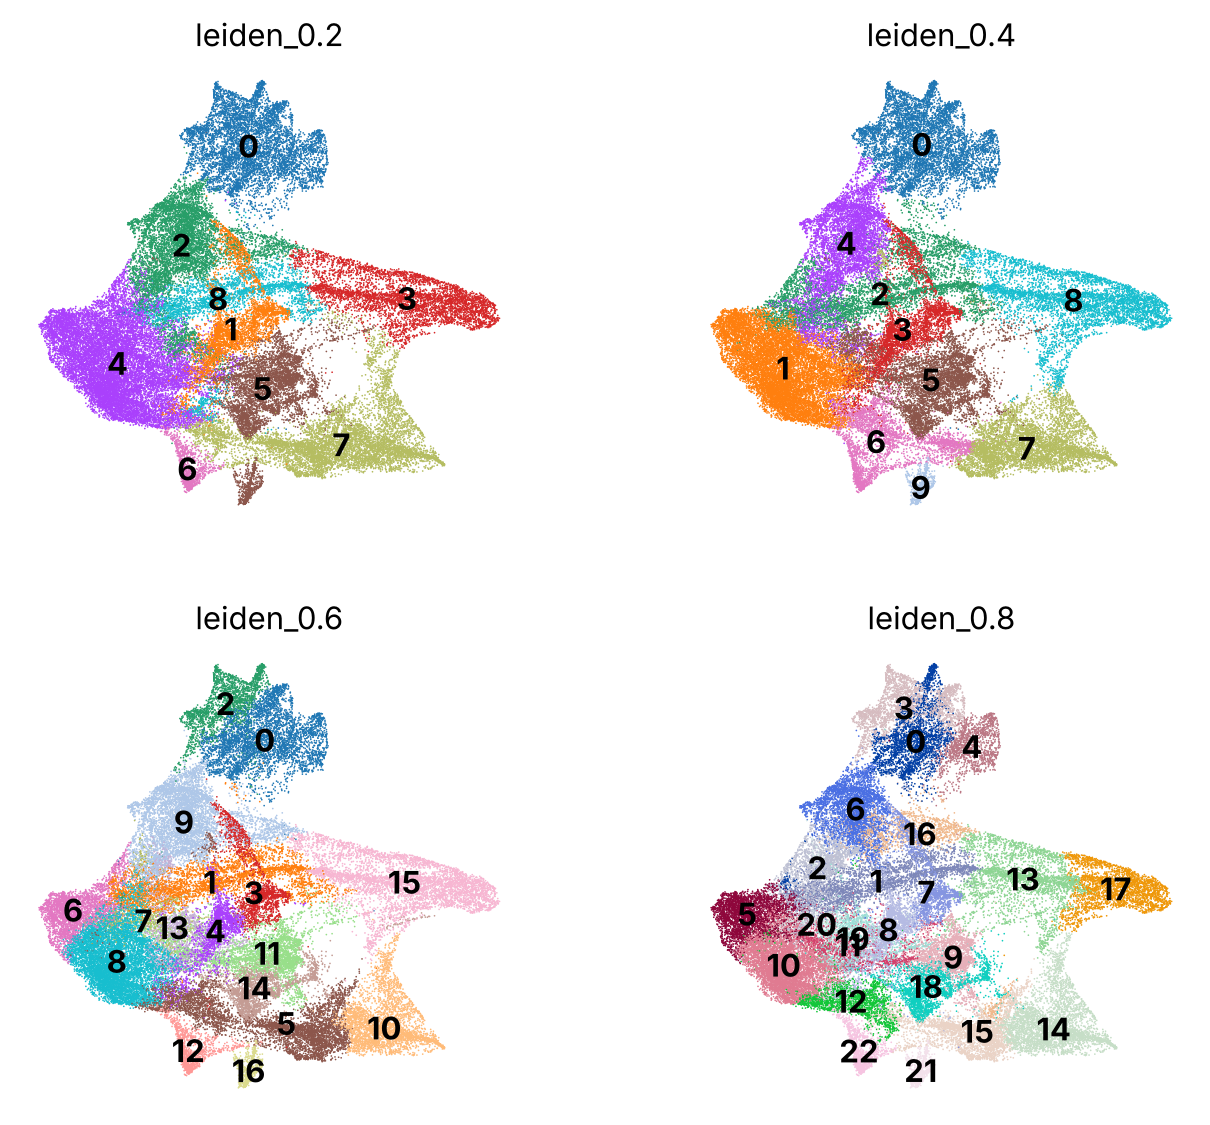

In [9]:
resolutions = [0.2, 0.4, 0.6, 0.8]
for r in resolutions:
    sc.tl.leiden(
        combined,
        resolution=r,
        key_added=f'leiden_{r}',
        flavor='igraph',
        n_iterations=2,
        directed=False,
        random_state=0,
    )
    n = combined.obs[f'leiden_{r}'].nunique()
    print(f'Resolution {r}: {n} clusters')

sc.pl.umap(
    combined,
    color=[f'leiden_{r}' for r in resolutions],
    ncols=2,
    frameon=False,
    legend_loc='on data',
)

**Result.** The four resolutions give 9, 10, 17, and 23 clusters. Resolution 0.2 and 0.4 give nearly the same partition; 0.4 additionally separates a small, distinct cluster at the bottom of the UMAP (later labeled Intestine). At 0.6 and 0.8, large uniform regions (for example the muscle region at the top and the large region on the left) are cut into several adjacent pieces with no visible boundary between them, which looks like over-splitting. I use **resolution 0.4 (10 clusters)** for the rest of the analysis. The other resolutions are kept in `obs` (`leiden_0.2`, …) for later comparison.

## 6. Marker genes and preliminary cell-type labels

**What.**
1. Find marker genes for each cluster with a Wilcoxon rank-sum test (each cluster vs all other spots).
2. Translate the top 30 markers per cluster from planarian SMED IDs to human gene symbols.
3. Score each cluster against lists of known lineage markers and assign the best-matching label.

**Why.** Planarian genes have few functional annotations, so the human ortholog symbol is the most practical way to recognize known marker genes. Only about half of the SMED IDs have a BLAST hit, so some top markers have no symbol and are skipped.

**Parameters.** A cluster gets the label whose marker list has the most overlap with its top 30 markers. The lineage marker lists are canonical planarian markers (as human orthologs), extended with genes that turned up in this dataset's marker lists.

In [10]:
combined.obs['leiden'] = combined.obs['leiden_0.4']

sc.tl.rank_genes_groups(combined, groupby='leiden', method='wilcoxon')

# Translate top-30 SMED markers per cluster to human gene symbols
N_TOP = 30
top_smed = pd.DataFrame(combined.uns['rank_genes_groups']['names']).head(N_TOP)
top_sym = top_smed.map(lambda g: id2sym.get(g, ''))

# Print non-empty symbols per cluster to help with annotation
print('Non-empty symbols per cluster:')
for col in top_sym.columns:
    syms = [s for s in top_sym[col] if s]
    print(f'  Cluster {col}: {syms}')

Non-empty symbols per cluster:
  Cluster 0: ['PLAC8L1', 'DOHH', 'MYH7', 'VIL1', 'PCCA', 'PCCB', 'HSPG2', 'COL6A6', 'PCK2', 'ALDOA', 'ACTG1', 'CHDH', 'CAPN9']
  Cluster 1: ['PLIN5', 'PANK4', 'CTSL', 'HPGDS', 'PSAP', 'TUBA1A', 'PSAPL1', 'CTSB', 'COTL1', 'ACTB', 'POR', 'CTSV', 'CTSD', 'ACTG1', 'PDPK1', 'AL159163.1']
  Cluster 2: ['KLK13', 'GM2A', 'MEP1A', 'CPA2', 'LIPF', 'NPC2', 'KLK13', 'PLB1', 'PRSS33', 'TPPP3', 'AC099489.1', 'GAA']
  Cluster 3: ['PPIC', 'MUC2', 'PPIC', 'RUBCN', 'NOVA2', 'P4HA2', 'PIWIL1', 'PIWIL1', 'PIWIL1', 'TUBB4B', 'PPIA', 'TUBB4B', 'SET', 'FSCN1', 'SUMF2', 'PCYT1A', 'GRN', 'RNF170', 'TUBA3C', 'CLCA4', 'ZAN']
  Cluster 4: ['TSPAN5', 'TSPO', 'TSPAN3', 'PLAC8', 'TLL2', 'HPN', 'MMP7', 'CALU', 'PDIA2', 'MME', 'ASTL', 'ASTL', 'MMP13', 'ASTL', 'CPA2', 'GLIPR1L1', 'P4HB', 'PI16', 'PI16', 'ECE1']
  Cluster 5: ['TG', 'TG', 'NID2', 'P4HB', 'HHAT', 'PDIA4', 'SLC16A14']
  Cluster 6: ['GRN', 'MRC1', 'PIWIL1', 'PPIA', 'H2AC20', 'PIWIL1', 'EEF1A1', 'PIWIL1', 'SET', 'H3-3A', 'TUBA3

In [11]:
# Canonical planarian lineage markers (human orthologs),
# expanded to include genes actually observed in this dataset
lineage_markers = {
    'Neoblast':        ['PIWIL1', 'PIWIL2', 'DDX4', 'MCM2', 'MCM5',
                        'MKI67', 'TOP2A', 'H2AFX', 'HPGDS'],
    'Neural':          ['ELAVL3', 'ELAVL4', 'SYT1', 'SNAP25', 'GAD1',
                        'CHAT', 'TH', 'PRSS12', 'TPPP3', 'MAPT'],
    'Muscle':          ['MYOD1', 'MYH1', 'MYH6', 'MYH7', 'TPM1',
                        'TPM2', 'ACTN2', 'CSRP3'],
    'Epidermal':       ['KRT8', 'KRT18', 'KRT19', 'VIM', 'CALML5'],
    'Intestine':       ['HNF4A', 'GATA4', 'CTSL', 'APOB',
                        'NKX2-2', 'MUC2', 'PRSS1', 'VIL1'],
    'Protonephridia':  ['POU3F3', 'SIX1', 'EYA1', 'OSR1'],
    'Pharynx':         ['FOXA1', 'FOXA2', 'LAMC1', 'TG'],
    'Cathepsin+':      ['CTSD', 'CTSB', 'CTSL', 'TSPO', 'PLIN5'],
    'Parenchymal':     ['PLAC8', 'PLAC8L1', 'TSPAN5', 'TSPAN3',
                        'RCN2', 'CALU', 'LMNA'],
}

def assign_type(symbols):
    sym_set = {s.upper() for s in symbols if s}
    scores = {
        ct: sum(m in sym_set for m in marks)
        for ct, marks in lineage_markers.items()
    }
    best = max(scores, key=scores.get)  # ties go to the first list above
    return best if scores[best] > 0 else 'Unknown'

cluster_type = {c: assign_type(top_sym[c].tolist()) for c in top_sym.columns}
print('Cluster -> cell type:')
for k, v in cluster_type.items():
    print(f'  Cluster {k}: {v}')

combined.obs['cell_type'] = (
    combined.obs['leiden'].astype(str).map(cluster_type).astype('category')
)

Cluster -> cell type:
  Cluster 0: Muscle
  Cluster 1: Cathepsin+
  Cluster 2: Neural
  Cluster 3: Neoblast
  Cluster 4: Parenchymal
  Cluster 5: Pharynx
  Cluster 6: Parenchymal
  Cluster 7: Parenchymal
  Cluster 8: Neural
  Cluster 9: Intestine


**Result.** The overlap rule gives clear labels for most clusters: cluster 0 as Muscle (MYH7, PLAC8L1), cluster 1 as Cathepsin+ (CTSB, CTSD, CTSL, PLIN5), cluster 5 as Pharynx (TG), and cluster 9 as Intestine (many cathepsins, VIL1). Two calls are weak:
- Cluster 2 is labeled Neural from a single marker (TPPP3), but most of its other top markers are digestive enzymes (KLK13, MEP1A, CPA2, LIPF), so it may be gut-related.
- Cluster 6 is labeled Parenchymal from PLAC8 and RCN2, although PIWIL1 appears three times among its top markers. This is revisited in Section 7.

These labels are a first pass. Later notebooks use the cell2location estimates that come with the dataset as the main cell-type measure.

## 7. Neoblast clusters

**What.**
1. Score every spot for a neoblast gene module (PIWIL1/2, DDX4, MCM2/5, MKI67, TOP2A, H2AFX) with `sc.tl.score_genes`.
2. Average the score within each cluster.
3. Check the score and individual markers on the UMAP.

**Why.** Neoblasts are the adult stem cells that drive regeneration and the only dividing cells in planarians, so they express both stem-cell genes (PIWI family, DDX4) and cell-cycle genes (MCM, MKI67, TOP2A). A module score is more robust than any single gene, because each gene alone is sparse in Visium data. The score compares each spot's average expression of these genes against a random set of genes with similar expression levels, so a score above 0 means the program is enriched.

**Decision rule.** A cluster is called neoblast-enriched if (1) its mean score is above 0.4 and (2) PIWIL1 is among its top 30 markers. PIWIL1 is the human ortholog of *smedwi-1*, the standard pan-neoblast marker in planarians. The score cutoff sits in the gap between the clearly high clusters and the rest (see the bar plot below). These clusters are relabeled as Neoblast, overriding the overlap rule from Section 6.

Neoblast marker IDs found in data (10): ['SMED30001362', 'SMED30007406', 'SMED30014446', 'SMED30035892', 'SMED30022978', 'SMED30031463', 'SMED30006979', 'SMED30032563', 'SMED30001991', 'SMED30015481']


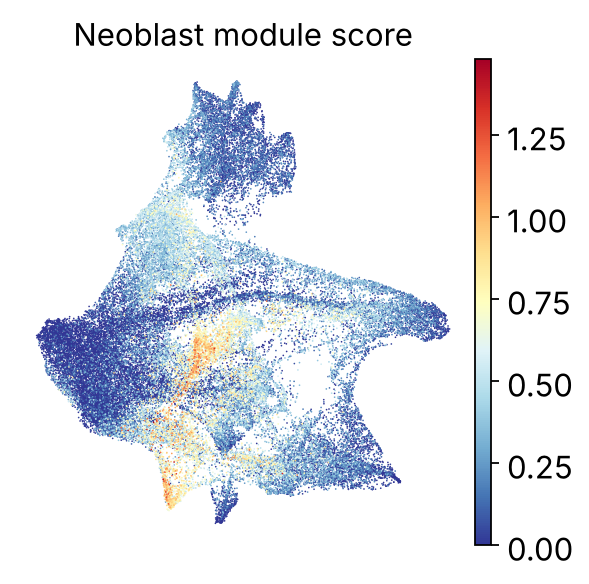

In [12]:
def resolve_ids(symbols):
    # Return the SMED IDs present in the dataset for a list of human symbols
    ids = []
    for s in symbols:
        ids += [g for g in sym2ids.get(s, []) if g in combined.var_names]
    return list(dict.fromkeys(ids))  # deduplicate, preserve order

neoblast_symbols = ['PIWIL1', 'PIWIL2', 'DDX4', 'MCM2', 'MCM5',
                    'MKI67', 'TOP2A', 'H2AFX']
neoblast_ids = resolve_ids(neoblast_symbols)
print(f'Neoblast marker IDs found in data ({len(neoblast_ids)}):', neoblast_ids)

sc.tl.score_genes(combined, gene_list=neoblast_ids,
                  score_name='neoblast_score', random_state=0)

sc.pl.umap(combined, color='neoblast_score', title='Neoblast module score',
           cmap='RdYlBu_r', frameon=False, vmin=0)

leiden  mean_neoblast_score   cell_type
     3             0.608209    Neoblast
     6             0.545430 Parenchymal
     4             0.340225 Parenchymal
     5             0.241854     Pharynx
     8             0.199670      Neural
     7             0.144340 Parenchymal
     0             0.096219      Muscle
     2             0.069081      Neural
     9             0.021028   Intestine
     1            -0.027867  Cathepsin+


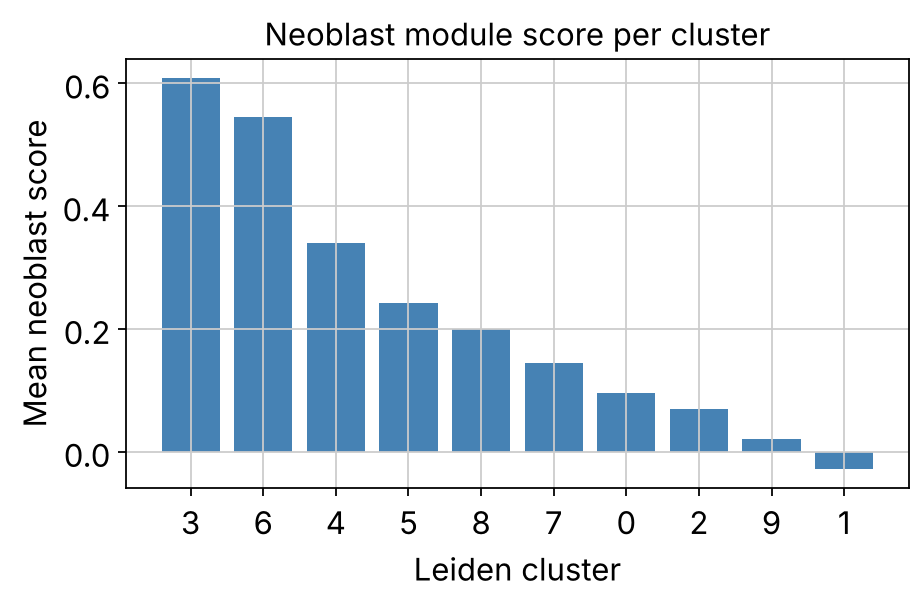

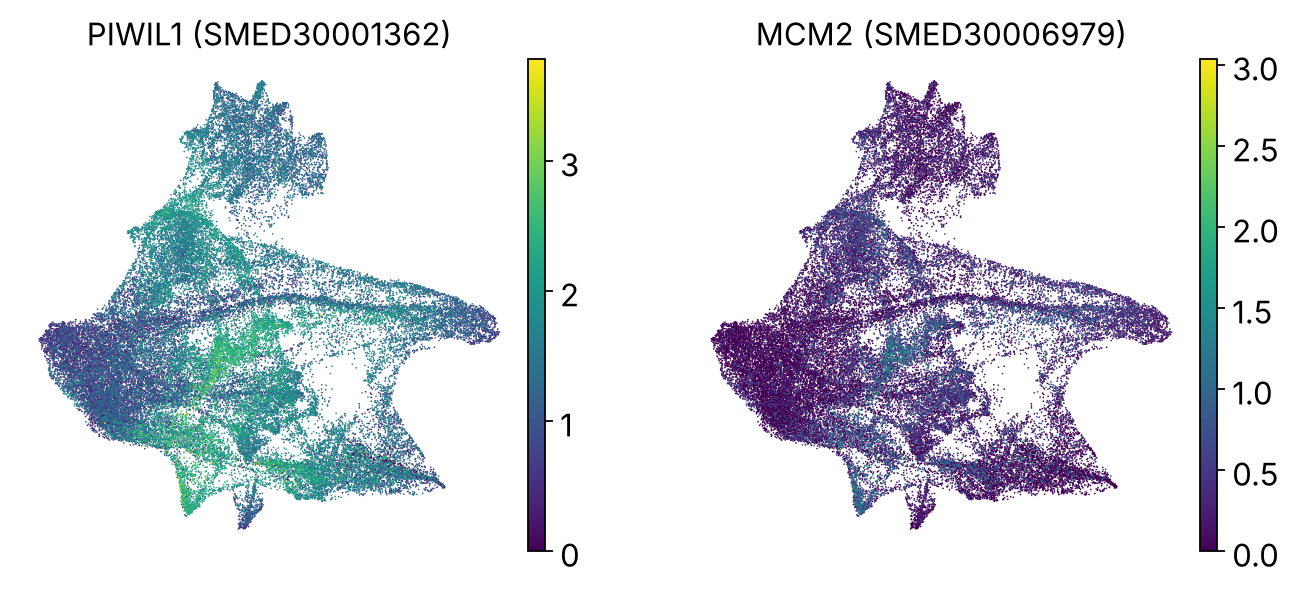

In [13]:
cluster_scores = (
    combined.obs.groupby('leiden', observed=True)['neoblast_score']
    .mean()
    .sort_values(ascending=False)
    .rename('mean_neoblast_score')
    .reset_index()
)
cluster_scores['cell_type'] = cluster_scores['leiden'].map(cluster_type)
print(cluster_scores.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(cluster_scores['leiden'].astype(str),
       cluster_scores['mean_neoblast_score'], color='steelblue')
ax.set_xlabel('Leiden cluster')
ax.set_ylabel('Mean neoblast score')
ax.set_title('Neoblast module score per cluster')
plt.tight_layout()
plt.show()

# Individual canonical neoblast genes on the UMAP
probe_ids, probe_labels = [], []
for sym in ['PIWIL1', 'PIWIL2', 'MCM2', 'MKI67']:
    ids = resolve_ids([sym])
    if ids:
        probe_ids.append(ids[0])
        probe_labels.append(f'{sym} ({ids[0]})')

sc.pl.umap(combined, color=probe_ids, title=probe_labels, ncols=2,
           frameon=False, cmap='viridis')

In [14]:
# Apply the decision rule and relabel neoblast-enriched clusters
SCORE_CUTOFF = 0.4
neoblast_clusters = [
    c for c, s in zip(cluster_scores['leiden'], cluster_scores['mean_neoblast_score'])
    if s > SCORE_CUTOFF and 'PIWIL1' in top_sym[c].values
]
print('Neoblast-enriched clusters:', neoblast_clusters)
for c in neoblast_clusters:
    print(f'  Cluster {c}: {cluster_type[c]} -> Neoblast')
    cluster_type[c] = 'Neoblast'

combined.obs['cell_type'] = (
    combined.obs['leiden'].astype(str).map(cluster_type).astype('category')
)
print()
print(combined.obs['cell_type'].value_counts())

Neoblast-enriched clusters: ['3', '6']
  Cluster 3: Neoblast -> Neoblast
  Cluster 6: Parenchymal -> Neoblast

cell_type
Parenchymal    11612
Cathepsin+     11282
Neural         10089
Neoblast        7021
Muscle          6271
Pharynx         5996
Intestine        585
Name: count, dtype: int64


**Result.** Clusters 3 (mean score 0.61) and 6 (0.55) stand clearly above the rest (next highest: cluster 4 at 0.34), and both have PIWIL1 among their top markers. On the UMAP, the module score and PIWIL1/MCM2 expression are highest in the same central band. Both clusters are labeled Neoblast (7,021 spots, 13% of all spots); cluster 6 changes from Parenchymal to Neoblast. Cluster 4 has a moderate score but no PIWIL1 among its top markers, so it stays Parenchymal. Because each spot covers several cells, it may hold spots that mix neoblasts with differentiated cells.

## 8. Final labels and marker dot plot

**What.** The UMAP colored by the final labels, and a dot plot of 2–4 representative markers per label, shown by their human symbols.

**Why.** The dot plot is a compact check that each label is backed by its own markers: dot size shows the fraction of spots expressing the gene, color shows mean expression (scaled per gene). A clean label should light up mainly on its own markers.

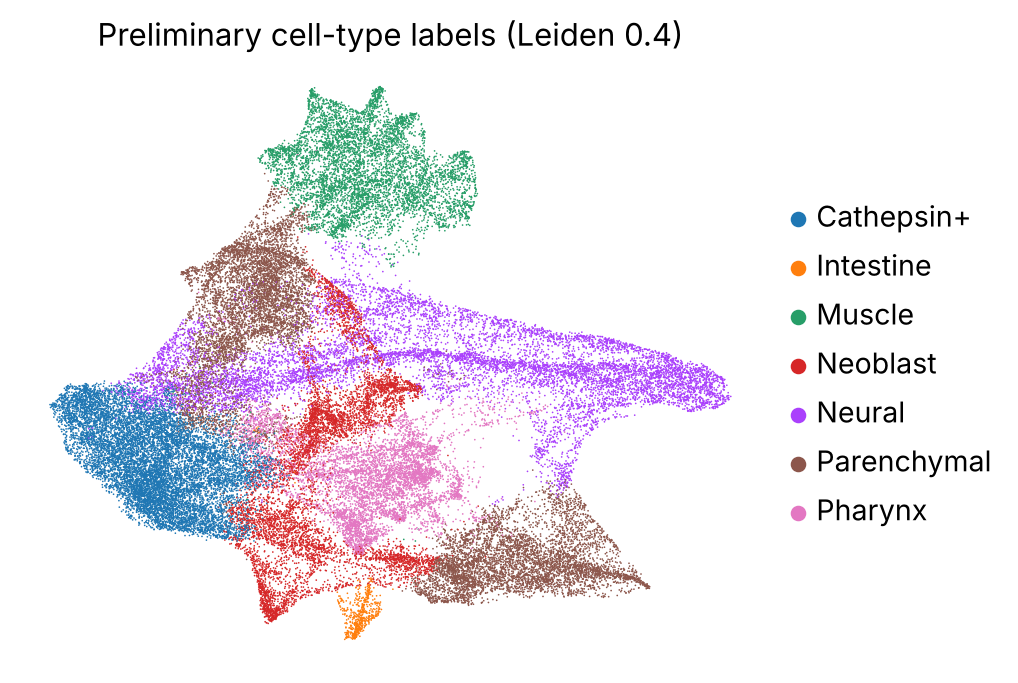

In [15]:
fig, ax = plt.subplots(figsize=(6, 5))
sc.pl.umap(combined, color='cell_type', ax=ax, show=False, frameon=False,
           title='Preliminary cell-type labels (Leiden 0.4)',
           legend_loc='right margin')
fig.savefig(f'{FIG_DIR}/01_umap_cell_types.png', dpi=150, bbox_inches='tight')
plt.show()

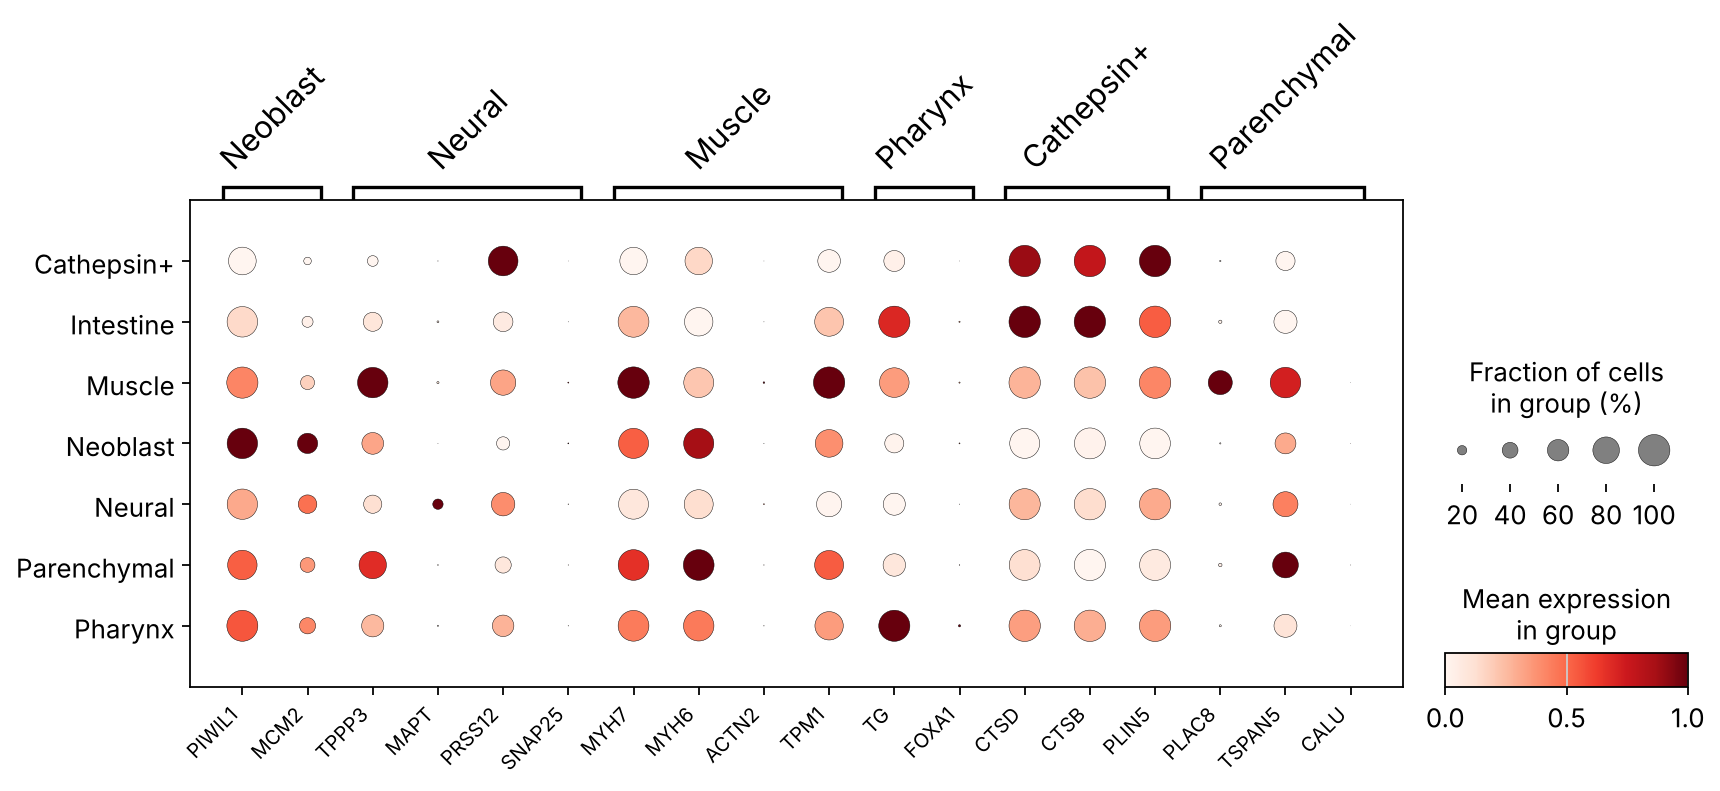

In [16]:
dotplot_markers = {
    'Neoblast':    ['PIWIL1', 'PIWIL2', 'MCM2', 'MKI67'],
    'Neural':      ['TPPP3', 'MAPT', 'PRSS12', 'SNAP25'],
    'Muscle':      ['MYH7', 'MYH6', 'ACTN2', 'TPM1'],
    'Pharynx':     ['TG', 'FOXA1'],
    'Cathepsin+':  ['CTSD', 'CTSB', 'PLIN5'],
    'Parenchymal': ['PLAC8', 'TSPAN5', 'CALU'],
}

def resolve_one(symbol):
    # Return the first SMED ID for a symbol that exists in the dataset
    for sid in sym2ids.get(symbol, []):
        if sid in combined.var_names:
            return sid
    return None

panel_ids, panel_labels = {}, {}
for ct, syms in dotplot_markers.items():
    if ct not in combined.obs['cell_type'].cat.categories:
        continue
    ids = []
    for sym in syms:
        sid = resolve_one(sym)
        if sid and sid not in ids:
            ids.append(sid)
            panel_labels[sid] = sym
    if ids:
        panel_ids[ct] = ids

ax_dict = sc.pl.dotplot(
    combined, var_names=panel_ids, groupby='cell_type',
    standard_scale='var', figsize=(12, 4),
    var_group_rotation=45,
    show=False,
)
ax = ax_dict['mainplot_ax']
ax.set_xticklabels(
    [panel_labels.get(t.get_text(), t.get_text()) for t in ax.get_xticklabels()],
    rotation=45, ha='right', fontsize=9,
)
plt.savefig(f'{FIG_DIR}/01_marker_dotplot.png', dpi=150, bbox_inches='tight')
plt.show()

**Result.**
- Neoblast spots have the highest PIWIL1 and MCM2, which supports the Section 7 call.
- Pharynx is defined by TG, and Muscle by MYH7 and TPM1.
- Cathepsin+ and Intestine share high CTSD and CTSB, which fits both being gut-associated.
- The Neural label is the least reliable. TPPP3 is highest in Muscle and PRSS12 in Cathepsin+, and the classic neural markers (MAPT, SNAP25) are barely detected in any group. Together with the cluster 2 issue in Section 6, this suggests the Neural group is partly mislabeled.
- Several markers (MAPT, SNAP25, ACTN2, FOXA1, CALU) are barely detected anywhere, likely because of sparse Visium capture or weak ortholog mapping.

## 9. Save the processed data

The saved object contains the log-normalized matrix (`X`), raw counts (`layers['counts']`), the corrected embedding (`obsm['X_pca_harmony']`), both UMAPs, the Leiden clusters at all four resolutions, the preliminary labels, and the neoblast score. Later notebooks load this file instead of rerunning the steps above.

In [17]:
out_path = f'{OUT_DIR}/01_integrated.h5ad'
combined.write_h5ad(out_path, compression='gzip')
print('Saved', out_path, combined.shape)

Saved ../data/processed/01_integrated.h5ad (52856, 22333)


## Summary

**What this notebook produced**
- A combined dataset of 52,856 spots × 22,333 genes from six timepoints, after removing 1% of spots in QC.
- A Harmony-corrected embedding in which the six timepoints are well mixed.
- Ten Leiden clusters (resolution 0.4) with preliminary labels: Parenchymal, Cathepsin+, Neural, Neoblast, Muscle, Pharynx, and Intestine.
- Two neoblast-enriched clusters (13% of spots), supported by both the module score and PIWIL1.

**Limitations**
- Labels come from marker overlap on BLAST-mapped orthologs. Neoblast, Muscle, Pharynx, and Cathepsin+ are well supported; Neural is not.
- Timepoint is both the batch and the biological variable, so Harmony may also remove some real change over time. Comparisons across timepoints should use the expression matrix, not the corrected embedding.
- Spots are not single cells, so clusters describe tissue composition.
- Batch correction was done per timepoint only, not per capture area (`library_id`).

More detail on these points is in [`docs/notes.md`](../docs/notes.md).

**Next:** the downstream analysis (`02_analysis.ipynb`) uses the cell2location proportions to follow neural tissue loss and regrowth at the wound.